# Cvičení 2: První model v PuLP krok za krokem

Řešení.

Otevřete notebook v Jupyteru nebo Google Colabu. Buňky spouštějte shora dolů pomocí Shift+Enter. Hlavní příklad i krátké demonstrace obsahují úplný kód; v sekci 9 je malý úkol k samostatnému doplnění a v sekci 10 doplňkové srovnání knihoven. Data jsou modelová.

Používáme Python 3.12 nebo novější a **PuLP 3.3.2**, stejně jako v ostatních cvičeních. Nejprve spusťte instalační buňku v sekci 0; případný požadavek na restart jádra (v Colabu relace) se zobrazí přímo v jejím výstupu. Následující kód je určen pro tuto verzi; PuLP 4 má jiné rozhraní.

## 0. Příprava prostředí — spusťte jako první
Tato buňka nainstaluje **PuLP 3.3.2** do prostředí aktuálního notebooku, pokud
správná verze chybí. Stačí ji spustit; příkazy není potřeba upravovat.

Pokud už máte v paměti PuLP 4, buňka po instalaci výpočet zastaví a vyzve
k **restartu relace/jádra**. V Colabu otevřete nabídku **Runtime (Běhové prostředí)**
a zvolte restart relace; v Jupyteru **Kernel → Restart Kernel**. Potom spusťte
notebook znovu shora. Samotné opakování `import pulp` starou verzi z paměti neodstraní.
Po hlášení „Připraveno“ můžete pokračovat. Instalace vyžaduje připojení k internetu.

In [1]:
import sys
import subprocess
from importlib.metadata import version, PackageNotFoundError

REQUIRED_PULP = "3.3.2"
try:
    installed_pulp = version("pulp")
except PackageNotFoundError:
    installed_pulp = None

if installed_pulp != REQUIRED_PULP:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet",
        "--disable-pip-version-check", "--no-cache-dir", "pulp==3.3.2"
    ])
if version("pulp") != REQUIRED_PULP:
    raise RuntimeError("PuLP 3.3.2 se nenainstalovalo. Zkontrolujte výpis instalace výše.")

loaded_pulp = sys.modules.get("pulp")
if loaded_pulp is not None and getattr(loaded_pulp, "__version__", None) != REQUIRED_PULP:
    raise RuntimeError(
        "PuLP 3.3.2 je nainstalované, ale v paměti zůstává jiná verze. "
        "V Colabu zvolte Runtime > Restart session (případně Restart runtime). "
        "V Jupyteru zvolte Kernel > Restart Kernel. Potom spusťte všechny buňky shora."
    )
print("Připraveno: PuLP 3.3.2 je nainstalované. Pokračujte dalšími buňkami.")

Připraveno: PuLP 3.3.2 je nainstalované. Pokračujte dalšími buňkami.


## Co si dnes vyzkoušíme
Od slovního zadání přejdeme k matematickému modelu a potom k několika řádkům Pythonu.
Naučíme se rozlišovat **model**, **řešič** a **výsledek**.

## 1. Které knihovny připadají v úvahu?
| Knihovna | Jak se v ní pracuje |
|---|---|
| [PuLP](https://github.com/coin-or/pulp/tree/3.3.2) | Vytvoříme pojmenované proměnné a zapisujeme výrazy a omezení podobně jako na papíře. Umí zadat LP i celočíselné a smíšené modely. |
| [SciPy: `scipy.optimize.linprog`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linprog.html) | Lineární program zadáváme pomocí vektoru koeficientů účelové funkce, matic omezení a mezí. |
| [Pyomo](https://pyomo.readthedocs.io/en/stable/getting_started/index.html) | Modelovací knihovna pro řadu optimalizačních úloh, včetně lineárních, celočíselných i nelineárních modelů. |
| [OR-Tools](https://developers.google.com/optimization/lp/mpsolver) | Sada optimalizačních nástrojů; rozhraní `MPSolver` umožňuje sestavovat LP a smíšené celočíselné modely. |

Dnes použijeme **PuLP pro zápis modelu** a **CBC jako řešič**, který hledá řešení.
Nejde o dva názvy téže věci. V doplňkové sekci 10 porovnáme PuLP s dalšími knihovnami.

### Načtení knihovny
`import pulp` zpřístupní knihovnu. Před její příkazy budeme psát `pulp.`.
Číslo verze nám umožní zkontrolovat, že používáme prostředí uvedené v úvodu.

In [2]:
import pulp
if pulp.__version__ != "3.3.2":
    raise RuntimeError("Spusťte nejprve sekci 0 a restartujte jádro podle pokynů.")
print(pulp.__version__)

3.3.2


## 2. Zadání: dvě kapalné směsi
Malá výrobna připravuje **směs A a směs B**. Plánujeme jednu výrobní dávku.
Rozhodujeme, kolik litrů každé směsi vyrobíme. Obě množství mohou být
libovolná nezáporná reálná čísla: například 1,5 litru je dovoleno.

Obě směsi využívají **tentýž stroj a tutéž surovinu**. Pro celou dávku
máme nejvýše **6 minut stroje a 4,5 kg této suroviny**. Další omezení nejsou.
Vše, co vyrobíme, také prodáme. Příspěvky k zisku již zohledňují náklady
na příslušný litr; žádný další pevný náklad do modelu nepřidáváme.

| Údaj na jeden litr | Směs A | Směs B |
|---|---:|---:|
| Příspěvek k zisku [Kč/l] | 40 | 30 |
| Čas stroje [min/l] | 2 | 1 |
| Spotřeba společné suroviny [kg/l] | 1 | 1 |

Spotřeby a příspěvky se sčítají a jsou přímo úměrné množství.
Například 1,5 litru směsi A spotřebuje 3 minuty stroje a 1,5 kg suroviny
a přinese 60 Kč. **Hledáme plán s nejvyšším celkovým ziskem.**

Než začneme psát kód, pojmenujeme proměnné:
$x$ je množství směsi A v litrech a $y$ je množství směsi B v litrech.

### Model na papíře
$$\begin{aligned}
\max\quad &40x+30y &&\text{(zisk v Kč)},\\
\text{za podmínek}\quad &2x+y\le6 &&\text{(čas stroje v minutách)},\\
&x+y\le4{,}5 &&\text{(spotřeba suroviny v kg)},\\
&x,y\ge0 &&\text{(spojitá množství v litrech)}.
\end{aligned}$$
Každá část modelu teď dostane vlastní řádek kódu.

## 3. Sestavení modelu po krocích
### Krok 1: prázdná maximalizační úloha
`LpProblem` vytvoří objekt modelu. Řetězec `"mixtures"` je jeho název.
`LpMaximize` určuje maximalizaci; pro minimalizaci bychom použili `LpMinimize`.
Při opakovaném sestavování začněte znovu touto buňkou a pokračujte dolů,
aby se omezení nepřidávala podruhé do již hotového modelu.

In [3]:
model = pulp.LpProblem("mixtures", pulp.LpMaximize)

### Krok 2: proměnné a jejich obory
`LpVariable` vytvoří rozhodovací proměnnou. `lowBound=0` stanoví nezápornost;
bez tohoto argumentu by dolní mez nebyla zadána. `cat="Continuous"` dovoluje
neceločíselné hodnoty. Horní mez jednotlivých proměnných zde zvlášť nezadáváme.
Pythonové `x` odkazuje na proměnnou pojmenovanou `"x"`; zatím to není nalezené číslo.

In [4]:
x = pulp.LpVariable("x", lowBound=0, cat="Continuous")
y = pulp.LpVariable("y", lowBound=0, cat="Continuous")

### Krok 3: účelová funkce
Operátor `+=` zde přidává část modelu. **Výraz bez nerovnosti nebo rovnosti**
se použije jako účelová funkce. `"profit"` je její název. Násobení zapisujeme
hvězdičkou: `40*x`. Přidáním dalšího samotného výrazu bychom účelovou funkci
nahradili, nikoli k ní přidali další omezení.

In [5]:
model += 40*x + 30*y, "profit"

### Krok 4: omezení na čas stroje
Výraz s `<=` vytvoří omezení. Obě spotřeby se sčítají, protože směsi
využívají společný čas stroje. Název `"machine"` usnadní kontrolu výpisu.

In [6]:
model += 2*x + y <= 6, "machine"

### Krok 5: omezení na surovinu
V Pythonu píšeme desetinnou tečku: `4.5`. Nerovnost ve směru $\ge$ se zapisuje
`>=` a rovnost v omezení `==`. Jedno `=` slouží k přiřazení v Pythonu.

In [7]:
model += x + y <= 4.5, "material"

### Krok 6: kontrola zapsaného modelu
`print(model)` vypíše, co jsme skutečně zadali. Ještě nic neřeší.
Ve výpisu najděte `MAXIMIZE`, účelovou funkci, dvě pojmenovaná omezení
a spojité proměnné. Případná konstanta `+ 0` účelovou funkci nemění.
PuLP 3.3.2 ve výpisu `x Continuous` nulovou dolní mez neuvádí.
Nezápornost jsme zadali pomocí `lowBound=0`, nikoli slovem `Continuous`;
dolní meze proto ještě vypíšeme zvlášť pomocí atributu `lowBound`.

In [8]:
print(model)
print("Dolní mez x:", x.lowBound)
print("Dolní mez y:", y.lowBound)

mixtures:
MAXIMIZE
40*x + 30*y + 0
SUBJECT TO
machine: 2 x + y <= 6

material: x + y <= 4.5

VARIABLES
x Continuous
y Continuous

Dolní mez x: 0
Dolní mez y: 0


## 4. Spuštění řešiče a čtení výsledku
### Nejprve stav
`PULP_CBC_CMD` zvolí CBC. `msg=False` vypne jeho podrobný průběžný výpis;
pro jeho zobrazení lze použít `msg=True`. `solve` teprve spouští výpočet.
V použité verzi PuLP vrací **číselný kód stavu, nikoli optimální hodnotu**.
`LpStatus` převede tento kód na čitelný název.

In [9]:
solver = pulp.PULP_CBC_CMD(msg=False)
status = model.solve(solver)
print("Kód stavu:", status)
print("Stav:", pulp.LpStatus[status])

Kód stavu: 1
Stav: Optimal


### Potom hodnoty proměnných a účelové funkce
V této úloze očekáváme `Optimal` (kód `1`). Podmínka `if` dovolí číst
hodnoty až po této kontrole; odsazené řádky se provedou jen při splnění podmínky.
`x.value()` vrací hodnotu proměnné, `pulp.value(model.objective)` hodnotu účelové funkce.
Funkce `print` jen zobrazuje zvolené údaje; popisky a jednotky doplňujeme sami.

Tyto malé úlohy necháváme dopočítat bez časového limitu. Při předčasném
ukončení většího celočíselného výpočtu je třeba navíc kontrolovat podrobný
stav řešení (`model.sol_status`) a zprávu řešiče: nalezený přípustný plán
ještě nemusí mít prokázanou optimalitu.

In [10]:
if status == pulp.LpStatusOptimal:
    print("Směs A [l]:", x.value())
    print("Směs B [l]:", y.value())
    print("Zisk [Kč]:", pulp.value(model.objective))
else:
    print("Nebylo potvrzeno optimum. Stav:", pulp.LpStatus[status])

Směs A [l]: 1.5
Směs B [l]: 3.0
Zisk [Kč]: 150.0


Výsledek znamená: vyrobit **1,5 litru A a 3 litry B**, se ziskem **150 Kč**.
Číslo `1` vrácené metodou `solve()` je kód `Optimal`; zisk čteme zvlášť.

### Kontrola dosazením do zadání
Neomezíme se na slovo `Optimal`. Přepočítáme spotřeby a zisk z nalezených množství.
Rezerva je zde dostupné množství zdroje minus jeho spotřeba.

In [11]:
if status == pulp.LpStatusOptimal:
    print("Čas [min]:", 2*x.value() + y.value(), "z 6")
    print("Surovina [kg]:", x.value() + y.value(), "ze 4.5")
    print("Rezerva času [min]:", 6 - (2*x.value() + y.value()))
    print("Rezerva suroviny [kg]:", 4.5 - (x.value() + y.value()))
    print("Zisk přepočtený ze zadání [Kč]:", 40*x.value() + 30*y.value())

Čas [min]: 6.0 z 6
Surovina [kg]: 4.5 ze 4.5
Rezerva času [min]: 0.0
Rezerva suroviny [kg]: 0.0
Zisk přepočtený ze zadání [Kč]: 150.0


Oba zdroje jsou vyčerpány. Nezápornost také platí: obě nalezená množství jsou kladná.
U jiných dat mohou ve výpisu vzniknout velmi malé numerické odchylky od nuly;
kontroly v počítači proto obvykle používají malou toleranci.

## 5. Stejná data, jiné obory proměnných
Každou variantu sestavíme jako **nový model s novými proměnnými**.
Původní `model`, `x` a `y` tak zůstávají pro porovnání.

### Obě proměnné celočíselné: ILP
Nyní prodáváme obě směsi jen v celých litrových baleních a nic nevyrábíme
do zásoby. Množství v litrech proto musejí být celá: $x,y\in\mathbb{Z}_{\ge0}$.
Cíl i kapacity zůstávají stejné; měníme `cat` na `"Integer"`.

In [12]:
integer_model = pulp.LpProblem("whole_containers", pulp.LpMaximize)
x_i = pulp.LpVariable("x_i", lowBound=0, cat="Integer")
y_i = pulp.LpVariable("y_i", lowBound=0, cat="Integer")
integer_model += 40*x_i + 30*y_i, "profit"
integer_model += 2*x_i + y_i <= 6, "machine"
integer_model += x_i + y_i <= 4.5, "material"
status_i = integer_model.solve(pulp.PULP_CBC_CMD(msg=False))
print(pulp.LpStatus[status_i])
if status_i == pulp.LpStatusOptimal:
    print("x =", x_i.value(), "y =", y_i.value())
    print("Zisk [Kč]:", pulp.value(integer_model.objective))

Optimal
x = 2.0 y = 2.0
Zisk [Kč]: 140.0


Dostáváme **2 litry A a 2 litry B**, zisk **140 Kč**. Spotřeba je 6 minut a 4 kg.
Výpis `2.0` je číselný formát Pythonu; hodnota přitom splňuje celočíselnost.

**Zaokrouhlení spojitého optima není metoda řešení ILP.** Plán $(2,3)$ by
spotřeboval 7 minut a 5 kg, takže není přípustný. Plán $(1,3)$ sice přípustný je,
ale přinese jen 130 Kč, méně než nalezené optimum.

### Jen jedna proměnná celočíselná: MILP
Směs A nadále prodáváme jen v celých litrových baleních, ale směs B lze
prodávat v libovolném množství. Nyní je $x$ celočíselné a $y$ spojité.
Takový model nazýváme **smíšeným celočíselným lineárním programem (MILP)**.

In [13]:
mixed_model = pulp.LpProblem("mixed_containers", pulp.LpMaximize)
x_m = pulp.LpVariable("x_m", lowBound=0, cat="Integer")
y_m = pulp.LpVariable("y_m", lowBound=0, cat="Continuous")
mixed_model += 40*x_m + 30*y_m, "profit"
mixed_model += 2*x_m + y_m <= 6, "machine"
mixed_model += x_m + y_m <= 4.5, "material"
status_m = mixed_model.solve(pulp.PULP_CBC_CMD(msg=False))
print(pulp.LpStatus[status_m])
if status_m == pulp.LpStatusOptimal:
    print("x =", x_m.value(), "y =", y_m.value())
    print("Zisk [Kč]:", pulp.value(mixed_model.objective))

Optimal
x = 1.0 y = 3.5
Zisk [Kč]: 145.0


Dostáváme **1 litr A a 3,5 litru B**, zisk **145 Kč**. Spotřeba je 5,5 minuty a 4,5 kg.

| Model | Obor $x$ | Obor $y$ | Nalezený plán $(x,y)$ [l] | Zisk [Kč] |
|---|---|---|---|---:|
| LP | spojitá | spojitá | (1,5; 3) | 150 |
| ILP | celočíselná | celočíselná | (2; 2) | 140 |
| MILP | celočíselná | spojitá | (1; 3,5) | 145 |

Přidáním požadavku na celočíselnost zmenšujeme přípustnou množinu.
Při stejném maximalizačním cíli proto nemůžeme získat vyšší optimum.
Pro rozhodnutí ano/ne existuje také `cat="Binary"`, tedy hodnoty 0 a 1;
v dnešním výrobním příkladu je nepotřebujeme.

## 6. Více optimálních řešení
Vrátíme se ke **spojitým** množstvím a původním kapacitám. Tentokrát
maximalizujeme **celkový objem** $x+y$ v litrech, nikoli zisk v Kč.

In [14]:
volume_model = pulp.LpProblem("total_volume", pulp.LpMaximize)
x_v = pulp.LpVariable("x_v", lowBound=0, cat="Continuous")
y_v = pulp.LpVariable("y_v", lowBound=0, cat="Continuous")
volume_model += x_v + y_v, "volume"
volume_model += 2*x_v + y_v <= 6, "machine"
volume_model += x_v + y_v <= 4.5, "material"
status_v = volume_model.solve(pulp.PULP_CBC_CMD(msg=False))
print(pulp.LpStatus[status_v])
if status_v == pulp.LpStatusOptimal:
    print("x =", x_v.value(), "y =", y_v.value())
    print("Objem [l]:", pulp.value(volume_model.objective))

Optimal
x = 0.0 y = 4.5
Objem [l]: 4.5


Řešič vrátí **jeden** optimální plán se stavem `Optimal`. Tím neříká,
že je optimum jediné, a automaticky nevypíše všechny optimální plány.
Konkrétní vrácený plán se může mezi řešiči lišit.

Dvě různá optima ověříme přímo ze zadání:

| Plán $(x,y)$ [l] | Čas [min] | Surovina [kg] | Celkový objem [l] |
|---|---:|---:|---:|
| (0; 4,5) | 4,5 | 4,5 | 4,5 |
| (1; 3,5) | 5,5 | 4,5 | 4,5 |

Oba plány jsou nezáporné a splňují obě omezení. Větší objem než 4,5 litru
zakazuje přímo omezení na surovinu. **Oba plány jsou tedy optimální.**
Samotná shoda dvou hodnot účelové funkce by k důkazu optimality nestačila.

## 7. Model bez přípustného řešení
K původnímu spojitému výrobnímu modelu přidáme objednávku **alespoň 5 litrů celkem**.
Před spuštěním si všimněte rozporu: surovina dovoluje $x+y\le4{,}5$,
ale objednávka vyžaduje $x+y\ge5$. Žádný plán nemůže splnit obě podmínky.

In [15]:
infeasible_model = pulp.LpProblem("impossible_order", pulp.LpMaximize)
x_f = pulp.LpVariable("x_f", lowBound=0, cat="Continuous")
y_f = pulp.LpVariable("y_f", lowBound=0, cat="Continuous")
infeasible_model += 40*x_f + 30*y_f, "profit"
infeasible_model += 2*x_f + y_f <= 6, "machine"
infeasible_model += x_f + y_f <= 4.5, "material"
infeasible_model += x_f + y_f >= 5, "order"
status_f = infeasible_model.solve(pulp.PULP_CBC_CMD(msg=False))
print(pulp.LpStatus[status_f])

Infeasible


Stav `Infeasible` znamená, že model **nemá přípustné řešení**.
Není to syntaktická chyba Pythonu a nemusí vzniknout výjimka: výpočet skončí stavem,
který musíme zkontrolovat. Příčinou zde jsou neslučitelné požadavky.

U proměnných mohou i po takovém výpočtu zůstat nějaká čísla. **Nepovažujeme je
za přípustný ani optimální plán** a hodnotu účelové funkce nehlásíme jako optimum.

## 8. Krátké srovnání: neomezená úloha
Samostatný minipříklad: maximalizujeme $u$ při jediné podmínce $u\ge0$.
Přípustná řešení existují, například $u=0$, ale každou hodnotu lze zlepšit:
zvolíme prostě větší $u$. Účelová funkce není shora omezená.

In [16]:
unbounded_model = pulp.LpProblem("no_upper_bound", pulp.LpMaximize)
u = pulp.LpVariable("u", lowBound=0, cat="Continuous")
unbounded_model += u, "objective"
status_u = unbounded_model.solve(pulp.PULP_CBC_CMD(msg=False))
print(pulp.LpStatus[status_u])

Unbounded


Stav je `Unbounded`. Neexistuje konečná optimální hodnota ani optimální plán;
nejde o případ bez přípustných řešení. Samotná neomezenost přípustné množiny
by ještě neznamenala neomezenost účelové funkce.

### Přehled stavů v PuLP 3.3.2
| Stav | Kód | Co z něj čteme |
|---|---:|---|
| `Optimal` | 1 | V našich dokončených výpočtech bylo nalezeno optimum; nemusí být jediné. |
| `Infeasible` | -1 | Omezení nelze splnit současně. |
| `Unbounded` | -2 | Účelovou funkci lze zlepšovat bez konečné meze. |
| `Not Solved` | 0 | Model zatím není vyřešen; tento stav nedokazuje nepřípustnost. |
| `Undefined` | -3 | Není k dispozici jednoznačný závěr; je třeba prohlédnout zprávu řešiče. |

Poslední dva stavy zde uměle nevyvoláváme. Také chybějící spustitelný řešič
nebo chybný kód je něco jiného než matematická nepřípustnost modelu.

## 9. Krátký samostatný úkol
Vraťte se k původním **spojitým** proměnným a maximalizaci zisku $40x+30y$.
Změňte pouze zásobu suroviny ze 4,5 na **4 kg**. V nové buňce sestavte nový
model, vyřešte jej a vypište stav, obě množství a zisk. Dosazením ověřte obě kapacity.
Zkuste to bez kopírování hotového kódu; kroky 1 až 6 slouží jako nápověda.

In [17]:
practice_model = pulp.LpProblem("four_kg", pulp.LpMaximize)
x_p = pulp.LpVariable("x_p", lowBound=0, cat="Continuous")
y_p = pulp.LpVariable("y_p", lowBound=0, cat="Continuous")
practice_model += 40*x_p + 30*y_p, "profit"
practice_model += 2*x_p + y_p <= 6, "machine"
practice_model += x_p + y_p <= 4, "material"
status_p = practice_model.solve(pulp.PULP_CBC_CMD(msg=False))
print(pulp.LpStatus[status_p])
if status_p == pulp.LpStatusOptimal:
    print("x =", x_p.value(), "y =", y_p.value())
    print("Zisk [Kč]:", pulp.value(practice_model.objective))
    print("Čas [min]:", 2*x_p.value() + y_p.value(), "z 6")
    print("Surovina [kg]:", x_p.value() + y_p.value(), "ze 4")

Optimal
x = 2.0 y = 2.0
Zisk [Kč]: 140.0
Čas [min]: 6.0 z 6
Surovina [kg]: 4.0 ze 4


Výsledek je $x=2$, $y=2$ a zisk 140 Kč. Spotřebujeme všech 6 minut a 4 kg. Proměnné přesto zůstávají spojité: celočíselné hodnoty tentokrát vyšly z dat, nikoli z požadavku `cat="Integer"`.

## 10. Pro zajímavost: PuLP a další knihovny na větší úloze
Jak se liší zápis a rychlost téže úlohy v různých Pythonových knihovnách?
Porovnáme **PuLP, Pyomo, SciPy (`linprog`) a přímé rozhraní `highspy`**.
Všechny varianty používají **HiGHS**; mění se způsob, kterým model sestavíme
a předáme k řešení. `highspy` je přímé rozhraní k řešiči, zatímco PuLP a Pyomo
nabízejí symbolický zápis modelu. SciPy přijímá matice a vektory.

### Zadání a data
Výrobce může připravit **6 000 různých produktů**. U každého produktu rozhoduje
o podílu jedné výrobní dávky: $0\le x_j\le1$. Produkty společně využívají
**600 zdrojů**. Každý produkt spotřebovává právě 12 z nich.
Příspěvek celé dávky k zisku $p_j$ náhodně zvolíme mezi 10 a 100 Kč,
nenulovou spotřebu $a_{ij}$ mezi 1 a 10 jednotkami příslušného zdroje.
Ostatní spotřeby jsou nulové. Jde o umělá data pro výpočetní ukázku.

Kapacitu každého zdroje nastavíme na polovinu spotřeby, která by vznikla
při výrobě celé dávky všech produktů: $b_i=\frac12\sum_j a_{ij}$.
Model má tvar
$$\max\sum_{j=1}^{6000}p_jx_j,\qquad
\sum_{j=1}^{6000}a_{ij}x_j\le b_i\quad(i=1,\ldots,600),\qquad
0\le x_j\le1.$$
Polovina každé dávky, tedy všechna $x_j=0{,}5$, je přípustná.
Proměnné jsou omezené, takže optimum existuje a má konečnou hodnotu.

Pevné **semínko generátoru** zajistí stejná data při dalším spuštění ve stejném
prostředí. Ve výpisu je `n` počet proměnných, `m` počet kapacitních omezení
(bez mezí proměnných) a `nnz` počet nenulových spotřeb. Krátký otisk dat
umožní ověřit, že porovnáváme tutéž úlohu.

In [18]:
import random
import hashlib
import json

SEED = 20261016
N_PRODUCTS = 6000
N_RESOURCES = 600
RESOURCES_PER_PRODUCT = 12
rng = random.Random(SEED)

profit = [rng.randint(10, 100) for j in range(N_PRODUCTS)]
rows = [[] for i in range(N_RESOURCES)]
for j in range(N_PRODUCTS):
    for i in rng.sample(range(N_RESOURCES), RESOURCES_PER_PRODUCT):
        rows[i].append((j, rng.randint(1, 10)))
capacity = [0.5 * sum(a for j, a in row) for row in rows]

fingerprint = hashlib.sha256(
    json.dumps([profit, rows, capacity]).encode()
).hexdigest()[:16]
print("n =", N_PRODUCTS, "m =", N_RESOURCES)
print("nnz =", sum(len(row) for row in rows))
print("seed =", SEED, "SHA-256 (16) =", fingerprint)

n = 6000 m = 600
nnz = 72000
seed = 20261016 SHA-256 (16) = 9aafeb8801e6d560


### Příprava knihoven
Pro tuto doplňkovou sekci doinstalujte všechny porovnávané knihovny v samostatné buňce:

```python
%pip install pulp==3.3.2 pyomo==6.10.1 scipy==1.18.1 highspy==1.15.1 matplotlib
```

Poté restartujte jádro a spusťte notebook shora. Instalace a importy se neměří;
sekce 1–9 tyto doplňky nevyžadují. Pro tuto ukázku přepneme PuLP z CBC na HiGHS.
PuLP, Pyomo i přímé rozhraní používají stejný balíček `highspy`. SciPy má **vlastní
vestavěnou verzi HiGHS**, která se může lišit; proto vypíšeme obě verze.
To omezuje možnost připsat veškerý rozdíl jen režii knihovny.

In [19]:
import os
import platform
import subprocess
import warnings
import numpy as np
import scipy
from scipy.optimize import linprog, OptimizeWarning
from scipy.sparse import csr_matrix
import pyomo.environ as pyo
import highspy
from importlib.metadata import version

HIGHS_OPTIONS = dict(threads=1, solver="simplex", parallel="off",
                     simplex_strategy=1, presolve="on", random_seed=0)
print("Python:", platform.python_version())
for package in ("pulp", "pyomo", "scipy", "highspy", "numpy"):
    print(package + ":", version(package))
print("HiGHS přes highspy:", highspy.Highs().version())
# SciPy obsahuje vlastní HiGHS; neveřejný import slouží jen k výpisu verze.
try:
    from scipy.optimize._highspy import _core
    scipy_highs = ".".join(str(getattr(_core, "HIGHS_VERSION_" + part))
                           for part in ("MAJOR", "MINOR", "PATCH"))
except (ImportError, AttributeError):
    scipy_highs = "verze nezjištěna"
print("HiGHS uvnitř SciPy:", scipy_highs)
print("OS:", platform.system(), platform.release(), platform.machine())
cpu = platform.processor() or platform.machine()
if platform.system() == "Darwin":
    query = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"],
                           capture_output=True, text=True)
    if query.returncode == 0:
        cpu = query.stdout.strip()
print("CPU:", cpu, "logických CPU:", os.cpu_count())

Python: 3.12.14
pulp: 3.3.2
pyomo: 6.10.1
scipy: 1.18.1
highspy: 1.15.1
numpy: 2.5.3
HiGHS přes highspy: 1.15.1
HiGHS uvnitř SciPy: 1.12.0
OS: Darwin 25.5.0 arm64
CPU: Apple M5 Pro logických CPU: 18


### Stejný model ve čtyřech rozhraních
Ve všech čtyřech zápisech minimalizujeme záporný zisk:
$\min(-\sum_j p_jx_j)$ má stejná optimální řešení jako původní maximalizace.
Vrácenou účelovou hodnotu proto při výpisu zisku opět vynásobíme $-1$.

Každá funkce `prepare_…` vytvoří nový model či vstupní pole a vrátí funkci `solve`,
která model vyřeší a načte hodnoty. Toto rozdělení nám umožní měřit obě části.
Není potřeba znát všechny níže uvedené příkazy zpaměti; sledujte, jak se
proměnné, účelová funkce a omezení zapisují jinak.

#### PuLP: pojmenované proměnné a výrazy

In [20]:
def prepare_pulp():
    model = pulp.LpProblem("large_production", pulp.LpMinimize)
    x = [pulp.LpVariable(f"q_{j:05}", lowBound=0, upBound=1)
         for j in range(N_PRODUCTS)]
    model += pulp.lpSum(-profit[j] * x[j] for j in range(N_PRODUCTS))
    for i, row in enumerate(rows):
        model += pulp.lpSum(a * x[j] for j, a in row) <= capacity[i]
    solver = pulp.HiGHS(msg=False, **HIGHS_OPTIONS)

    def solve():
        status = model.solve(solver)
        ok = status == pulp.LpStatusOptimal and model.sol_status == pulp.LpSolutionOptimal
        return ok, [q.value() for q in x], -pulp.value(model.objective)
    return solve

#### Pyomo: proměnné, účelová funkce a omezení jako části modelu
Použijeme rozhraní `appsi_highs`. Každý běh vytvoří nový model i řešič,
takže nevyužíváme dříve nalezené řešení ani bázi.

In [21]:
def prepare_pyomo():
    model = pyo.ConcreteModel()
    model.x = pyo.Var(range(N_PRODUCTS), bounds=(0, 1))
    model.objective = pyo.Objective(
        expr=pyo.quicksum(-profit[j] * model.x[j] for j in range(N_PRODUCTS)),
        sense=pyo.minimize)
    model.resources = pyo.Constraint(range(N_RESOURCES), rule=lambda m, i:
        pyo.quicksum(a * m.x[j] for j, a in rows[i]) <= capacity[i])
    solver = pyo.SolverFactory("appsi_highs")
    solver.options.update(HIGHS_OPTIONS)

    def solve():
        result = solver.solve(model)
        ok = result.solver.termination_condition == pyo.TerminationCondition.optimal
        return ok, [pyo.value(model.x[j]) for j in range(N_PRODUCTS)], -pyo.value(model.objective)
    return solve

#### SciPy a highspy: maticový zápis
Ze stejných seznamů vytvoříme vektor `c`, řídkou matici `A` a pravou stranu `b`.
Řídká matice uchovává jen nenulové koeficienty a jejich pozice.
Tento převod je součástí měření a pro každou variantu se provede znovu.

In [22]:
def make_arrays():
    coefficients, columns, starts = [], [], [0]
    for row in rows:
        for j, a in row:
            columns.append(j)
            coefficients.append(a)
        starts.append(len(coefficients))
    A = csr_matrix((np.array(coefficients, dtype=float),
                    np.array(columns, dtype=np.int32),
                    np.array(starts, dtype=np.int32)),
                   shape=(N_RESOURCES, N_PRODUCTS))
    c = -np.array(profit, dtype=float)
    b = np.array(capacity, dtype=float)
    return c, A, b

SciPy dostane přímo nerovnosti `A @ x <= b` a meze `(0, 1)`.
`method="highs-ds"` volí duální simplexovou metodu; její principy dnes nepotřebujeme.
Volbu `threads=1` SciPy předává do HiGHS s upozorněním; potlačujeme pouze toto známé
upozornění o dodatečné volbě, nikoli chyby výpočtu.

In [23]:
def prepare_scipy():
    c, A, b = make_arrays()

    def solve():
        # SciPy předá threads do HiGHS, ale upozorní na dodatečnou volbu.
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", category=OptimizeWarning,
                                    message=r"Unrecognized options detected: \{'threads': 1\}\..*")
            result = linprog(c, A_ub=A, b_ub=b, bounds=(0, 1),
                             method="highs-ds", options={"threads": 1})
        return result.success and result.status == 0, result.x, -result.fun if result.success else None
    return solve

Přímé `highspy` dostane stejné koeficienty v objektu `HighsLp`.
Kód je podrobnější, protože sami vyplníme i vnitřní zápis řídké matice.
NumPy a SciPy zde slouží k přípravě polí a matice; samotné řešení voláme přes `highspy`.

In [24]:
def check_highs(status):
    if status != highspy.HighsStatus.kOk:
        raise RuntimeError(f"HiGHS: {status}")

def prepare_highspy():
    c, A, b = make_arrays()
    lp = highspy.HighsLp()
    lp.num_col_, lp.num_row_ = N_PRODUCTS, N_RESOURCES
    lp.col_cost_ = c
    lp.col_lower_, lp.col_upper_ = np.zeros(N_PRODUCTS), np.ones(N_PRODUCTS)
    lp.row_lower_, lp.row_upper_ = np.full(N_RESOURCES, -highspy.kHighsInf), b
    lp.a_matrix_.format_ = highspy.MatrixFormat.kRowwise
    lp.a_matrix_.start_, lp.a_matrix_.index_, lp.a_matrix_.value_ = A.indptr, A.indices, A.data
    solver = highspy.Highs()
    check_highs(solver.setOptionValue("output_flag", False))
    for option, value in HIGHS_OPTIONS.items():
        check_highs(solver.setOptionValue(option, value))

    def solve():
        check_highs(solver.passModel(lp))
        check_highs(solver.run())
        ok = solver.getModelStatus() == highspy.HighsModelStatus.kOptimal
        return ok, solver.getSolution().col_value, -solver.getObjectiveValue()
    return solve

### Co přesně měříme?
Hlavní údaj je **celkový čas od společných seznamů dat po načtené řešení**:
sestavení modelu nebo polí, vytvoření rozhraní řešiče, předání modelu, optimalizace
a načtení hodnot. Samostatně uvádíme sestavení a řešení s načtením.
Hranice mezi těmito částmi závisí na API; pro porovnání proto sledujte především **celek**.
Generování společných dat, importy, následné kontroly a vykreslení do času nepatří.

Použijeme duální simplexovou metodu HiGHS, jedno vlákno a zapnuté předzpracování.
Další výchozí volby se mohou mezi verzemi lišit. Každou variantu jednou zahřejeme,
potom provedeme **tři měření v rotovaném pořadí**, vždy s novými objekty a bez
předání předchozího řešení. Během měření nespouštějte další výpočty souběžně.

Po každém běhu ověříme optimalitu, meze proměnných, všechna původní omezení
a přepočtený zisk. Kontrolujeme i shodu zisků mezi knihovnami s numerickou tolerancí.
Chybný výsledek měření zastaví.

In [25]:
import gc
import math
from time import perf_counter
from statistics import median

PREPARE = {"PuLP": prepare_pulp, "Pyomo": prepare_pyomo,
           "SciPy linprog": prepare_scipy, "highspy": prepare_highspy}
REPEATS = 3

def run_once(name):
    gc.collect()
    start = perf_counter()
    solve = PREPARE[name]()
    built = perf_counter()
    optimal, values, reported_profit = solve()
    finished = perf_counter()

    if not optimal:
        raise RuntimeError(f"{name}: optimalita nebyla potvrzena")
    if not all(v is not None and math.isfinite(v) and -1e-7 <= v <= 1+1e-7 for v in values):
        raise RuntimeError(f"{name}: porušeny meze proměnných")
    violation = max(0.0, max(
        (sum(a * values[j] for j, a in row) - capacity[i]) / max(1.0, capacity[i])
        for i, row in enumerate(rows)))
    if violation > 1e-7:
        raise RuntimeError(f"{name}: porušena kapacitní omezení")
    objective = sum(p * v for p, v in zip(profit, values))
    if not math.isclose(objective, reported_profit, rel_tol=1e-7, abs_tol=1e-6):
        raise RuntimeError(f"{name}: nesouhlasí přepočet zisku")
    if not 0.5 * sum(profit) - 1e-6 <= objective <= sum(profit) + 1e-6:
        raise RuntimeError(f"{name}: zisk je mimo známé meze")
    return dict(library=name, build_s=built-start, solve_s=finished-built,
                total_s=finished-start, objective=objective, status="Optimal")

# Jeden zahřívací běh pro každou knihovnu; nepatří do souhrnu.
for name in PREPARE:
    run_once(name)

runs = []
names = list(PREPARE)
for repeat in range(REPEATS):
    order = names[repeat:] + names[:repeat]
    for name in order:
        result = run_once(name)
        runs.append(result)
        print(f"{repeat+1}: {name:13s} {result['total_s']:.3f} s  {result['status']}")
reference = runs[0]["objective"]
for run in runs:
    if not math.isclose(run["objective"], reference, rel_tol=1e-7, abs_tol=1e-6):
        raise RuntimeError("Knihovny vrátily rozdílné optimální hodnoty")

summary = []
for name in names:
    selected = [r for r in runs if r["library"] == name]
    totals = [r["total_s"] for r in selected]
    summary.append(dict(library=name, count=len(selected), status="Optimal",
                        total_s=median(totals), min_s=min(totals), max_s=max(totals),
                        build_s=median(r["build_s"] for r in selected),
                        solve_s=median(r["solve_s"] for r in selected),
                        objective=selected[-1]["objective"]))
summary.sort(key=lambda r: r["total_s"])

1: PuLP          2.351 s  Optimal


1: Pyomo         2.623 s  Optimal


1: SciPy linprog 2.173 s  Optimal


1: highspy       2.176 s  Optimal


2: Pyomo         2.620 s  Optimal


...

2: PuLP          2.337 s  Optimal


3: SciPy linprog 2.169 s  Optimal


3: highspy       2.176 s  Optimal


3: PuLP          2.352 s  Optimal


3: Pyomo         2.622 s  Optimal


### Výsledky měření
Tabulka je seřazena podle mediánu **celkového času** ze tří běhů.
Dílčí časy jsou rovněž mediány; jejich součet nemusí být přesně mediánem součtu.
Všechny uvedené běhy prošly kontrolou optimality a přípustnosti. Zisk umožňuje
porovnat výsledky. Uložené časy pocházejí z prostředí uvedeného výše;
po spuštění je nahradí vaše měření.

In [26]:
from IPython.display import Markdown, display

header = "| Knihovna | Sestavení [s] | Řešení + načtení [s] | Celkem [s] | Min–max celkem [s] | Zisk [Kč] |"
lines = [header, "|---|---:|---:|---:|---:|---:|"]
for row in summary:
    lines.append(f"| {row['library']} | {row['build_s']:.3f} | {row['solve_s']:.3f} | "
                 f"{row['total_s']:.3f} | {row['min_s']:.3f}–{row['max_s']:.3f} | "
                 f"{row['objective']:.3f} |")
display(Markdown("\n".join(lines)))

| Knihovna | Sestavení [s] | Řešení + načtení [s] | Celkem [s] | Min–max celkem [s] | Zisk [Kč] |
|---|---:|---:|---:|---:|---:|
| SciPy linprog | 0.006 | 2.166 | 2.172 | 2.169–2.173 | 230781.446 |
| highspy | 0.011 | 2.164 | 2.176 | 2.169–2.176 | 230781.446 |
| PuLP | 0.157 | 2.195 | 2.351 | 2.337–2.352 | 230781.446 |
| Pyomo | 0.067 | 2.553 | 2.622 | 2.620–2.623 | 230781.446 |

Délka pruhu ukazuje medián celkového času, úsečka rozsah minimum–maximum.
Nejde o interval spolehlivosti. Kratší pruh znamená rychlejší provedení této
konkrétní úlohy přes danou knihovnu na tomto počítači.

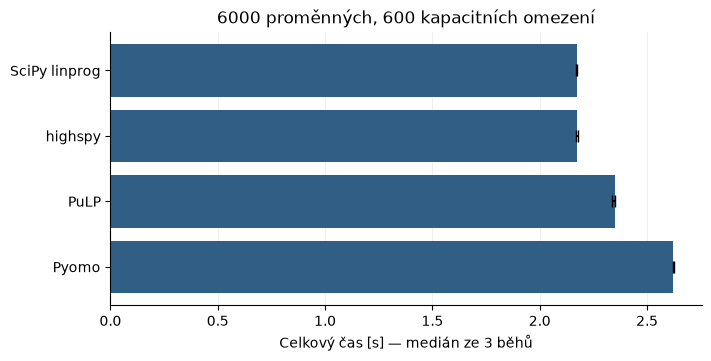

In [27]:
import matplotlib.pyplot as plt

medians = [r["total_s"] for r in summary]
errors = [[r["total_s"]-r["min_s"] for r in summary],
          [r["max_s"]-r["total_s"] for r in summary]]
fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
ax.barh([r["library"] for r in summary], medians, xerr=errors,
        color="#315e85", capsize=4)
ax.invert_yaxis()
ax.set_xlim(left=0)
ax.set_xlabel("Celkový čas [s] — medián ze 3 běhů")
ax.set_title(f"{N_PRODUCTS} proměnných, {N_RESOURCES} kapacitních omezení")
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### Jak srovnání číst
PuLP a Pyomo usnadňují symbolický zápis; SciPy a `highspy` očekávají podrobněji
připravená data. Čas sestavení ukazuje část ceny tohoto pohodlí, celkový čas
zahrnuje i převody a vlastní optimalizaci. Výsledek není univerzálním žebříčkem:
závisí na struktuře úlohy, způsobu zápisu, verzích a počítači. Rozdílná vestavěná
verze HiGHS ve SciPy navíc brání tomu, abychom vše připsali jen režii Pythonu.

Pro vlastní pokus změňte `N_PRODUCTS` na 3 000 nebo 12 000 a spusťte celou sekci 10
od vytvoření dat. Sledujte, jak se mění sestavení i celkový čas.

Rozhraní: [PuLP](https://github.com/coin-or/pulp/tree/3.3.2),
[Pyomo APPSI](https://pyomo.readthedocs.io/en/stable/reference/topical/appsi/appsi.html),
[SciPy linprog](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linprog.html)
a [highspy](https://ergo-code.github.io/HiGHS/stable/interfaces/python/example-py/).